# 01 — Validação dos dados de Orós
Objetivo: verificar qualidade da série de armazenamento e comparar as duas fontes (Portal Hidrológico CE × ANA/SAR).

In [6]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume, load_ana_history
from src.data.validators import validate_daily_series

portal = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
ana = load_ana_history('../data/raw/Histórico_ORÓS.xls')
print(portal.shape, ana.shape)

(7302, 2) (667, 7)


## 1. Qualidade de cada série

In [7]:
rp = validate_daily_series(portal)
ra = validate_daily_series(ana, value_col='useful_volume_hm3')
for n, r in (('Portal', rp), ('ANA', ra)):
    print(n, {k: (len(v) if isinstance(v, list) else v) for k, v in r.items()})
print('Portal — datas com volume vazio:'); portal[portal.volume_hm3.isna()]

Portal {'n_rows': 7302, 'start': Timestamp('2006-11-02 00:00:00'), 'end': Timestamp('2026-10-29 00:00:00'), 'duplicate_dates': 0, 'missing_dates': 0, 'is_sorted': True, 'invalid_values': 9}
ANA {'n_rows': 667, 'start': Timestamp('2025-01-01 00:00:00'), 'end': Timestamp('2026-10-29 00:00:00'), 'duplicate_dates': 0, 'missing_dates': 0, 'is_sorted': True, 'invalid_values': 0}
Portal — datas com volume vazio:


,date,volume_hm3
1503,2010-12-14,NaN
1731,2011-07-30,NaN
1732,2011-07-31,NaN
2543,2013-10-19,NaN
2544,2013-10-20,NaN
2545,2013-10-21,NaN
2592,2013-12-07,NaN
2593,2013-12-08,NaN
2594,2013-12-09,NaN


## 2. Série completa (Portal, 2006–2026)

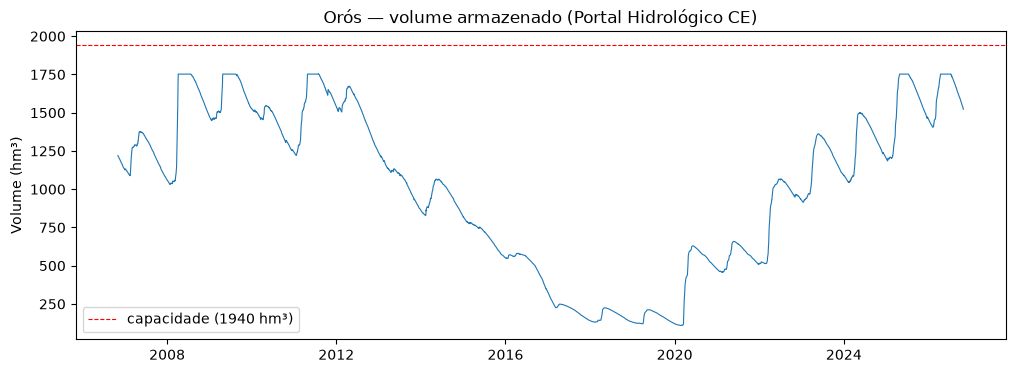

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(portal.date, portal.volume_hm3, lw=.8)
ax.axhline(1940, color='r', ls='--', lw=.8, label='capacidade (1940 hm³)')
ax.set_ylabel('Volume (hm³)'); ax.set_title('Orós — volume armazenado (Portal Hidrológico CE)'); ax.legend()
fig.savefig('../results/figures/01_portal_volume.png', dpi=150, bbox_inches='tight')

## 3. Portal × ANA no período comum

Máx. portal: 1752.36 | dias no máx.: 168
ANA > 100%: 144 dias; máx. 146.6 %
Dias idênticos: 109  primeira data: 2026-07-13 00:00:00


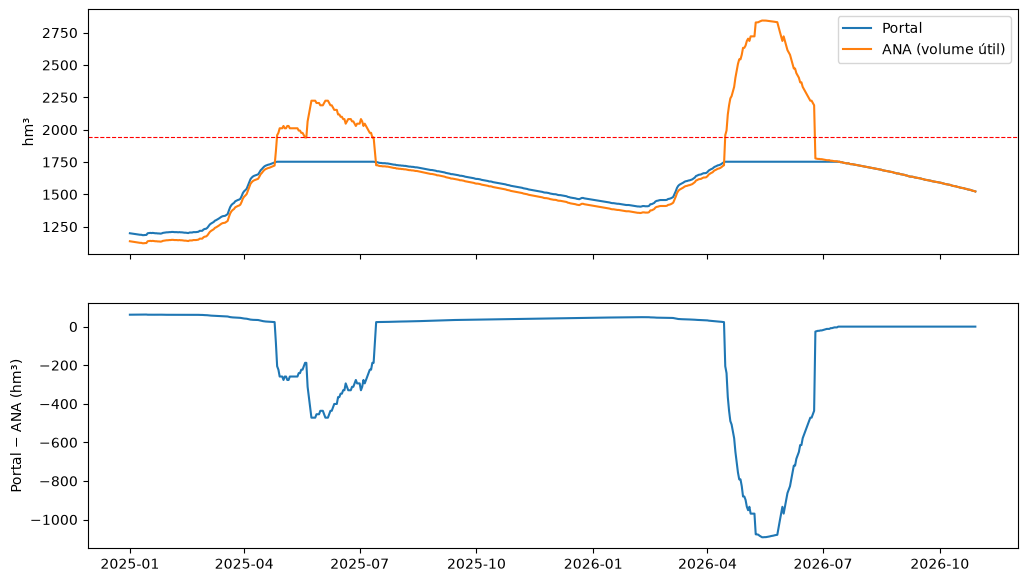

In [9]:
m = portal.merge(ana, on='date')
m['diff'] = m.volume_hm3 - m.useful_volume_hm3
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axs[0].plot(m.date, m.volume_hm3, label='Portal'); axs[0].plot(m.date, m.useful_volume_hm3, label='ANA (volume útil)')
axs[0].axhline(1940, color='r', ls='--', lw=.8); axs[0].set_ylabel('hm³'); axs[0].legend()
axs[1].plot(m.date, m['diff']); axs[1].set_ylabel('Portal − ANA (hm³)')
fig.savefig('../results/figures/01_portal_vs_ana.png', dpi=150, bbox_inches='tight')
print('Máx. portal:', portal.volume_hm3.max(), '| dias no máx.:', (m.volume_hm3 == portal.volume_hm3.max()).sum())
print('ANA > 100%:', (m.volume_pct > 100).sum(), 'dias; máx.', m.volume_pct.max(), '%')
print('Dias idênticos:', (m['diff'].abs() < 1e-9).sum(), ' primeira data:', m.loc[m['diff'].abs() < 1e-9, 'date'].min())

## 4. Achados
- **Portal:** 7.302 dias contínuos, sem duplicatas; 9 valores vazios (2010–2011) a tratar. O volume **satura em 1752,36 hm³**, abaixo da capacidade de 1940 hm³ (provável limite/cota do vertedouro — confirmar).

- **ANA:** 667 dias, sem lacunas. O volume "útil" **ultrapassa 100 %** (até ~147 %, em 144 dias) quando o Portal está saturado, ou seja, as duas fontes usam curvas cota–volume/definições distintas nesse regime.

- Em níveis baixos/médios as fontes diferem por ~30–60 hm³ (curva distinta); desde 13/07/2026 (109 dias idênticos) as séries são idênticas.

- **Consequência:** nenhuma das duas séries serve diretamente para vertimento/afluência acima da saturação. Para o balanço hídrico será preciso (i) escolher a fonte oficial, (ii) usar cota como variável de apoio e (iii) obter retiradas, evaporação e vertimentos.

- **Dados ainda necessários:** afluência, evaporação (INMET), retiradas e demandas setoriais.